# Un caviardage hybride regex + NER français détecte-t-il nettement plus de données personnelles que le regex seul sur du texte français, et à quelle latence ?

> **En bref.** Le NER français améliore nettement le caviardage par rapport aux regex seules, surtout pour les noms et adresses. Mais il laisse encore fuir une part importante de données, notamment des secrets, comptes et dates : il ne suffit pas seul. Rappel des spans : 0,657 [0,646 ; 0,669] pour Hybride regex + NER CamemBERT, contre 0,238 [0,228 ; 0,248] pour Regex seul (2926 exemples de test, échelle complète).

| | |
|---|---|
| **Question** | Sur du texte français annoté, le regex seul a un rappel de spans inférieur à 60 % (noms et adresses non détectés) alors que regex + NER CamemBERT dépasse 80 % de rappel, avec une latence médiane inférieure à 150 ms par document sur 2 cœurs CPU, et une précision supérieure à 70 %. |
| **Référence** | Regex seul — Expressions régulières pour e-mails, téléphones français, IBAN, URL, dates jj/mm/aaaa, sans modèle. |
| **Nouvelle approche** | Hybride regex + NER CamemBERT — Les regex captent les formats rigides ; un modèle de reconnaissance d'entités nommées français trouve personnes et lieux ; fusion des spans. |
| **Données publiques** | [`TheoDB/french-pii-eval`](https://huggingface.co/datasets/TheoDB/french-pii-eval) (default) |
| **Métrique principale** | Rappel des spans (à maximiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle complète (`SCALE = "full"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `fingerprint` | Empreinte courte (sha256) d'un jeu de données, pour la traçabilité des résultats. |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'text': 'text', 'spans': 'spans', 'source': 'source'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['Jean-Baptiste/camembert-ner'], 'full': ['Jean-Baptiste/camembert-ner']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = ['protobuf', 'sentencepiece']
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=full  SEED=42  device=cpu  python=3.12.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Avant d'envoyer un texte à un grand modèle de langage (LLM), on veut en retirer les **données personnelles** (PII) : noms, e-mails, téléphones, IBAN, adresses. Elles seraient sinon copiées chez le fournisseur, dans les journaux et dans les traces. Une étude récente, faite sur des CV synthétiques **anglais**, rapporte qu'un caviardeur « regex + NER » détecte 100 % des PII contre 88,9 % pour les regex seules, pour quelques millisecondes par document. Elle ne dit rien du **français**.

Cette expérience pose la question suivante : **sur du texte français annoté, un caviardage hybride regex + NER détecte-t-il nettement plus de données personnelles que les regex seules, et quelle latence ajoute-t-il ?**

### L'idée de la nouvelle approche

On peut comparer cela à deux relecteurs qui travaillent ensemble. Le premier connaît par cœur les **formats** (un IBAN commence par deux lettres et deux chiffres, un e-mail contient un « @ »). Le second **lit les phrases** et reconnaît qu'un « Mme Lefebvre » ou un « à Villeurbanne » désigne une personne ou un lieu, même sans format fixe.

1. **Regex** (expressions régulières) : on repère les formats rigides (e-mail, téléphone français, IBAN, URL, date, carte de paiement, IP, adresse postale avec type de voie).
2. **NER** (reconnaissance d'entités nommées) : le modèle français `Jean-Baptiste/camembert-ner` repère les personnes (`PER`) et les lieux (`LOC`).
3. **Fusion** : on réunit les zones (« spans ») qui se chevauchent.
4. **Remplacement** : chaque zone devient un jeton numéroté (`[PERSON_1]`, `[IBAN_1]`), pour que le LLM puisse encore distinguer deux personnes.

La référence s'arrête à l'étape 1, suivie des étapes 3 et 4.

### Ce que la comparaison permet de décider

- Si le **rappel** (part des PII annotées qui sont trouvées) de l'hybride dépasse nettement celui des regex, avec des intervalles de confiance disjoints, le modèle NER se justifie.
- La **précision** (part des zones caviardées qui étaient vraiment des PII) dit si l'hybride caviarde trop.
- La **latence** médiane et au 95e centile, sur 2 cœurs CPU, dit si son coût est acceptable devant un appel LLM, qui dure plusieurs secondes.

## 2. Les données

### Réglages des données

Le jeu public `TheoDB/french-pii-eval` contient des textes français avec des **spans** annotés, c'est-à-dire des intervalles de caractères `(début, fin, type)` qui délimitent chaque donnée personnelle.

Cette cellule importe les bibliothèques et fixe les réglages : jeu, split, nombre de textes tirés (`sample_size`) et minimum de textes exigé. Elle liste aussi les noms de champ reconnus pour le début, la fin et le type d'un span, car le format de `spans` varie d'une source à l'autre (le jeu public, lui, utilise des clés « type: valeur »).

In [6]:
import json
import random
import re
import time
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATASET_ID = "TheoDB/french-pii-eval"  # jeu français avec spans typés et split de test séparé
DATASET_CONFIG = "default"             # configuration unique du jeu
EVAL_SPLIT = "test"                    # split d'évaluation (2 926 textes)
N_DOCS = sample_size(reduced=150, full=None)  # 150 textes en réduit, tout le test en complet
MIN_TEST_DOCS = 100                    # en deçà, l'évaluation n'est pas concluante

START_KEYS = ("start", "begin", "start_offset", "char_start")  # noms possibles du début d'un span
END_KEYS = ("end", "stop", "end_offset", "char_end")           # noms possibles de la fin
LABEL_KEYS = ("type", "label", "entity_type", "entity_group", "entity", "tag")  # noms possibles du type
FIELD_KEYS = set(START_KEYS) | set(END_KEYS) | set(LABEL_KEYS)  # tous les noms de champ reconnus

### Lecture tolérante des valeurs brutes

Une colonne peut arriver sous plusieurs formes : texte JSON (parfois encodé deux fois), octets, tableau numpy ou valeur manquante.
- `as_python` ramène toutes ces formes à des objets Python ordinaires (listes, dictionnaires).
- `first_key` lit un champ dont le nom varie d'un jeu à l'autre (`start` ou `begin`, par exemple).

Le même lecteur servira pour les données internes.

In [7]:
def first_key(item: dict, keys: tuple):
    """Rend la valeur de la première clé de `keys` présente dans `item`, sinon None."""
    return next((item[key] for key in keys if key in item), None)


def as_python(raw):
    """Ramène une valeur de colonne (texte JSON, octets, tableau numpy) à des objets Python."""
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return []
    if isinstance(raw, bytes):
        raw = raw.decode("utf-8")
    if isinstance(raw, str):
        if not raw.strip():
            return []
        value = json.loads(raw)
        return as_python(value) if isinstance(value, str) else value  # JSON encodé deux fois
    if isinstance(raw, np.ndarray):
        return raw.tolist()
    return raw

### Format du jeu public : « type: valeur » vers intervalles

Dans `TheoDB/french-pii-eval`, le champ `spans` est un **dictionnaire** :
- chaque clé vaut `"type: valeur"`, par exemple `"account_number: PL0930…"` ;
- chaque valeur est la liste des intervalles `[début, fin]` où cette valeur apparaît (fin exclue).

`spans_from_label_map` garde le type (ce qui précède le premier « : ») et produit un span par intervalle, si bien qu'une valeur répétée donne plusieurs spans.

In [8]:
def spans_from_label_map(mapping: dict) -> list[dict]:
    """Spans d'un dictionnaire {"type: valeur": [[début, fin], ...]} (format du jeu public)."""
    spans = []
    for key, intervals in mapping.items():
        label = str(key).partition(":")[0].strip() or "UNKNOWN"
        intervals = as_python(intervals)
        if isinstance(intervals, (list, tuple)) and intervals and not isinstance(intervals[0], (list, tuple, np.ndarray)):
            intervals = [intervals]  # un seul intervalle écrit à plat
        for interval in intervals or []:
            interval = list(interval)
            if len(interval) >= 2:
                spans.append({"start": int(interval[0]), "end": int(interval[1]), "type": label})
    return spans

### Des spans bruts à une liste uniforme

`parse_spans` ramène les spans d'un document à une liste de `{start, end, type}`. Elle accepte quatre formats :
- le dictionnaire « type: valeur » vers intervalles (jeu public), reconnu parce que ses clés ne sont **pas** des noms de champ ;
- une liste de dictionnaires (format des données factices) ;
- une liste de triplets `[début, fin, type]` ;
- un dictionnaire de listes dont les clés sont des noms de champ (format « colonnes »).

Un élément sans début ou sans fin est ignoré. Un type absent devient `UNKNOWN`.

In [9]:
def parse_spans(raw) -> list[dict]:
    """Convertit les spans d'un document, quel que soit leur format, en liste de {start, end, type}."""
    items = as_python(raw)
    if isinstance(items, dict):
        if not set(items) & FIELD_KEYS:  # clés « type: valeur » : format du jeu public
            return spans_from_label_map(items)
        columns = {k: list(v) for k, v in items.items() if isinstance(v, (list, tuple, np.ndarray))}
        if columns and len(columns) == len(items):  # format « colonnes » : une liste par champ
            items = [dict(zip(columns, row)) for row in zip(*columns.values())]
        else:
            items = [items]
    spans = []
    for item in items or []:
        if isinstance(item, dict):
            start, end = first_key(item, START_KEYS), first_key(item, END_KEYS)
            label = first_key(item, LABEL_KEYS)
        elif isinstance(item, (list, tuple)) and len(item) >= 3:
            numbers = [x for x in item if isinstance(x, (int, float, np.integer)) and not isinstance(x, bool)]
            words = [x for x in item if isinstance(x, str)]
            if len(numbers) < 2:
                continue
            start, end, label = numbers[0], numbers[1], (words[0] if words else None)
        else:
            continue
        if start is None or end is None:
            continue
        spans.append({"start": int(start), "end": int(end), "type": str(label or "UNKNOWN")})
    return spans

### Assemblage des documents et tirage

- `prepare_documents` assemble chaque document `{text, spans, source}`. Elle écarte les spans **hors du texte** ou vides et compte combien elle en écarte : un nombre élevé signalerait un décalage d'indices.
- `sample_indices` tire les textes au hasard, sans remise, avec la graine de l'expérience. Les deux phases tirent donc leurs textes de la même façon.

In [10]:
def prepare_documents(texts, raw_spans, sources) -> tuple[list[dict], int]:
    """Assemble les documents {text, spans, source} ; rend aussi le nombre de spans invalides écartés."""
    documents, dropped = [], 0
    for text, raw, source in zip(texts, raw_spans, sources):
        text, spans = str(text), []
        for span in parse_spans(raw):
            valid = 0 <= span["start"] < span["end"] <= len(text)
            if valid and text[span["start"]:span["end"]].strip():
                spans.append(span)
            else:
                dropped += 1
        spans.sort(key=lambda s: (s["start"], s["end"]))
        documents.append({"text": text, "spans": spans, "source": str(source)})
    return documents, dropped


def sample_indices(n_total: int, n_wanted: int | None) -> list[int]:
    """Tire sans remise `n_wanted` indices parmi `n_total` (tous si None), avec la graine de l'expérience."""
    n_kept = n_total if n_wanted is None else min(n_wanted, n_total)
    rng = np.random.default_rng(SEED)
    return [int(i) for i in rng.choice(n_total, size=n_kept, replace=False)]

### Outils de contrôle chiffrés

Ces deux fonctions servent dans les deux phases :
- `documents_frame` met les documents sous forme de tableau (texte, canal, nombre et types de spans) ;
- `summarize_documents` affiche les effectifs par type et les longueurs. Elle compte aussi les spans **coupés au milieu d'un mot**, ce qui trahirait une fin incluse au lieu d'exclue.

In [11]:
def documents_frame(documents: list[dict]) -> pd.DataFrame:
    """Tableau des documents : texte, canal, nombre de spans et types présents."""
    return pd.DataFrame({
        "text": [d["text"] for d in documents],
        "source": [d["source"] for d in documents],
        "n_spans": [len(d["spans"]) for d in documents],
        "types": [", ".join(sorted({s["type"] for s in d["spans"]})) for d in documents],
    })


def summarize_documents(documents: list[dict]) -> None:
    """Affiche effectifs par type, longueurs (caractères) et part de spans coupés au milieu d'un mot."""
    rows = [{"type": s["type"], "chars": s["end"] - s["start"],
             "cut_word": s["end"] < len(d["text"]) and d["text"][s["end"] - 1].isalnum() and d["text"][s["end"]].isalnum()}
            for d in documents for s in d["spans"]]
    spans = pd.DataFrame(rows, columns=["type", "chars", "cut_word"])
    lengths = pd.Series([len(d["text"]) for d in documents])
    print(f"{len(documents)} textes, {len(spans)} spans annotés, "
          f"{(documents_frame(documents)['n_spans'] == 0).mean():.1%} de textes sans PII")
    print(f"Longueur des textes : médiane {lengths.median():.0f} caractères, max {lengths.max()}")
    print(f"Spans coupés au milieu d'un mot : {spans['cut_word'].mean():.1%} (proche de 0 attendu)")
    by_type = spans.groupby("type").agg(n_spans=("chars", "size"), median_chars=("chars", "median"))
    display(by_type.sort_values("n_spans", ascending=False))

### Figure de contrôle des données

`plot_documents` trace une figure à deux panneaux :
- à gauche, le **nombre de spans par type**, pour voir quels types ont assez d'exemples pour qu'un rappel par type ait du sens ;
- à droite, la **distribution des longueurs** de textes, dont dépend la latence du NER.

La figure est enregistrée par `save_figure` et sert aux deux phases.

In [12]:
def plot_documents(documents: list[dict], name: str, caption: str) -> None:
    """Figure à deux panneaux : nombre de spans par type et distribution des longueurs de textes."""
    counts = pd.Series([s["type"] for d in documents for s in d["spans"]]).value_counts()
    lengths = [len(d["text"]) for d in documents]
    fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
    left.barh(counts.index[::-1], counts.values[::-1], color=COLORS["accent"])
    left.set_xlabel("Nombre de spans annotés")
    left.set_title("Données personnelles par type")
    right.hist(lengths, bins=30, color=COLORS["reference"], alpha=0.85)
    right.set_xlabel("Longueur du texte (caractères)")
    right.set_ylabel("Nombre de textes")
    right.set_title("Longueur des textes")
    fig.tight_layout()
    save_figure(fig, name, caption)

### Chargement du jeu public

On charge le split `test`, on tire `N_DOCS` textes au hasard et on affiche le premier champ `spans` **brut**, pour vérifier le format que le lecteur a reconnu. Une valeur lue sur un exemple confirme que les indices tombent au bon endroit : le texte extrait doit être identique à la valeur écrite dans la clé. Ce bloc ne s'exécute qu'en phase publique.

In [13]:
if PHASE == "public":
    import datasets
    from datasets import load_dataset

    datasets.disable_progress_bars()
    raw_test = load_dataset(DATASET_ID, DATASET_CONFIG, split=EVAL_SPLIT)
    print("Colonnes :", raw_test.column_names)
    assert {"text", "spans"} <= set(raw_test.column_names), "colonnes text et spans attendues"
    chosen = sample_indices(len(raw_test), N_DOCS)
    subset = raw_test.select(chosen)
    print("Champ spans brut du premier texte :", repr(subset[0]["spans"])[:300])
    documents, n_dropped = prepare_documents(list(subset["text"]), list(subset["spans"]),
                                             ["public"] * len(subset))
    dataset_info = {"name": DATASET_ID, "config": DATASET_CONFIG, "split": EVAL_SPLIT}
    print(f"{len(documents)} textes tirés sur {len(raw_test)} ; spans invalides écartés : {n_dropped}")
    assert sum(len(d["spans"]) for d in documents) > 0, "aucun span lu : format de spans non reconnu"
    first = next(d for d in documents if d["spans"])
    print("Valeurs lues sur un exemple :", [(first["text"][s["start"]:s["end"]], s["type"]) for s in first["spans"]])

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Colonnes : ['text', 'spans', 'info']
Champ spans brut du premier texte : {'private_address: Apt. 814': [[17, 25]], 'private_address: 38789-2238': [[27, 37]]}
2926 textes tirés sur 2926 ; spans invalides écartés : 0
Valeurs lues sur un exemple : [('Apt. 814', 'private_address'), ('38789-2238', 'private_address')]


### Contrôles et aperçu

On regarde l'effectif de chaque type de donnée personnelle, puisque le rappel par type n'a de sens qu'avec assez d'exemples, et la longueur des textes, dont dépend la latence. On affiche ensuite quelques exemples.

2926 textes, 6838 spans annotés, 0.0% de textes sans PII
Longueur des textes : médiane 195 caractères, max 893
Spans coupés au milieu d'un mot : 0.6% (proche de 0 attendu)


,n_spans,median_chars
type,,
private_address,2004,9.0
private_person,1844,6.0
account_number,1157,16.0
private_date,588,10.0
secret,521,12.0
private_email,291,23.0
private_url,220,28.0
private_phone,213,14.0


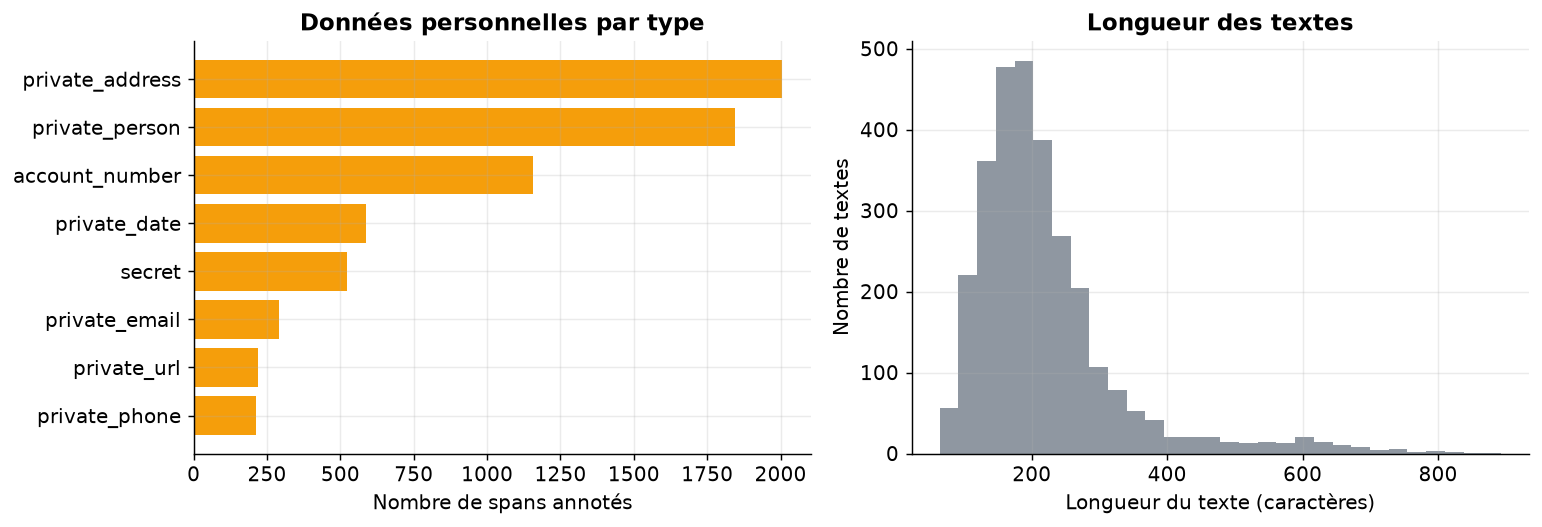

*Figure — À gauche, nombre de spans annotés par type de donnée personnelle dans l'échantillon de test ; à droite, distribution de la longueur des textes en caractères.*

In [14]:
if PHASE == "public":
    summarize_documents(documents)
    plot_documents(documents, "public_data_overview",
                   "À gauche, nombre de spans annotés par type de donnée personnelle dans l'échantillon de test ; "
                   "à droite, distribution de la longueur des textes en caractères.")
    preview(documents_frame(documents), n=5)

### Colonnes attendues et ingrédients du jeu factice

Les données internes comportent trois colonnes : le texte brut, ses spans annotés et le canal (e-mail, chat, transcription). Pour vérifier que tout le code tourne sans exposer de vraies données, on fabrique un **jeu factice** à partir de gabarits. Les noms, IBAN, téléphones et adresses sont inventés. Certains gabarits ne contiennent **aucune** donnée personnelle, mais des termes courants des services financiers qui doivent rester visibles.

In [15]:
PRIVATE_COLUMNS = {
    "text": "Texte brut (e-mail, ticket, transcription) avant caviardage",
    "spans": "Liste de spans annotés (start, end, type)",
    "source": "Canal : e-mail, chat, transcription",
}
N_FAKE_DOCS = 240  # assez de textes factices pour en tirer N_DOCS et avoir chaque type plus de 10 fois

FAKE_FIRST_NAMES = ["Camille", "Nathalie", "Mehdi", "Sophie", "Jean-Pierre", "Aurélie", "Thomas",
                    "Fatou", "Léa", "Grégoire", "Inès", "Yannick", "Bérénice", "Karim"]
FAKE_LAST_NAMES = ["Martin", "Lefebvre", "Benali", "Nguyen", "Moreau", "Da Silva", "Kowalski",
                   "Fontaine", "Diallo", "Roussel", "Garnier", "Le Goff", "Vasseur", "Ortega"]
FAKE_STREETS = ["rue des Lilas", "avenue Jean Jaurès", "boulevard Voltaire", "chemin du Moulin",
                "place de la République", "allée des Tilleuls", "impasse Victor Hugo"]
FAKE_CITIES = [("69003", "Lyon"), ("75011", "Paris"), ("33000", "Bordeaux"), ("59800", "Lille"),
               ("31000", "Toulouse"), ("44000", "Nantes"), ("67000", "Strasbourg")]
FAKE_DOMAINS = ["exemple.fr", "courriel.test", "messagerie.example"]
FAKE_TEMPLATES = {
    "e-mail": [
        "Bonjour, je suis {person} et je conteste un prélèvement sur mon compte {iban}. "
        "Vous pouvez me joindre au {phone} ou à {email}. Cordialement.",
        "Madame, Monsieur, suite à mon déménagement au {address}, merci de mettre à jour mon dossier. "
        "{person}, né(e) le {date}.",
        "Bonjour, quels sont les frais de tenue de compte pour l'offre Essentiel ? Merci d'avance.",
    ],
    "chat": [
        "Client : bonjour, ma carte de paiement est bloquée. Conseiller : pouvez-vous confirmer votre date "
        "de naissance ? Client : {date}, et mon nom est {person}.",
        "Client : le virement vers {person2} n'est pas arrivé, IBAN {iban}. Conseiller : je vérifie.",
        "Conseiller : le plafond de la carte de paiement est de 1 500 euros par mois.",
    ],
    "transcription": [
        "euh oui alors c'est {person} à l'appareil, je rappelle pour le prêt, mon numéro c'est le {phone}",
        "donc l'adresse c'est {address} et le mail {email} voilà, et ma conseillère c'est {person2}",
        "oui bonjour je voulais savoir si le taux du livret avait changé ce mois-ci",
    ],
}

### Valeurs fictives

`fake_values` invente un jeu de valeurs cohérent pour un texte, chaque valeur avec son type annoté :
- l'e-mail est construit à partir du nom, sans accents ;
- les téléphones (`06…` ou `+33 …`) et les IBAN (`FR76 …`) suivent le format français ;
- l'adresse combine un numéro, une voie, un code postal et une ville.

In [16]:
def fake_values(rng: random.Random) -> dict:
    """Invente un jeu de valeurs personnelles fictives, chacune avec son type annoté."""
    first, last = rng.choice(FAKE_FIRST_NAMES), rng.choice(FAKE_LAST_NAMES)
    other = f"{rng.choice(FAKE_FIRST_NAMES)} {rng.choice(FAKE_LAST_NAMES)}"
    login = unicodedata.normalize("NFKD", f"{first}.{last}").encode("ascii", "ignore").decode()
    digits = lambda k: "".join(str(rng.randint(0, 9)) for _ in range(k))
    phone = rng.choice(["0{} {} {} {} {}", "+33 {} {} {} {} {}"]).format(
        rng.choice("67"), *[digits(2) for _ in range(4)])
    postal_code, city = rng.choice(FAKE_CITIES)
    return {
        "person": (f"{first} {last}", "private_person"),
        "person2": (other, "private_person"),
        "email": (f"{login.lower().replace(' ', '')}@{rng.choice(FAKE_DOMAINS)}", "private_email"),
        "phone": (phone, "private_phone"),
        "iban": ("FR76 " + " ".join(digits(4) for _ in range(5)) + " " + digits(3), "account_number"),
        "date": (f"{rng.randint(1, 28):02d}/{rng.randint(1, 12):02d}/{rng.randint(1950, 2004)}", "private_date"),
        "address": (f"{rng.randint(1, 120)} {rng.choice(FAKE_STREETS)}, {postal_code} {city}", "private_address"),
    }

### Remplissage des gabarits

- `render_template` remplit un gabarit et note la position exacte de chaque valeur au moment où il l'insère. On obtient ainsi des spans de référence exacts par construction.
- `make_fake_data(n)` alterne les canaux, puis mélange les lignes avec la graine. Les spans sont écrits en **JSON**, comme dans un fichier exporté.

In [17]:
def render_template(template: str, values: dict) -> tuple[str, list[dict]]:
    """Remplit un gabarit et rend le texte avec la position exacte (start, end, type) de chaque valeur."""
    text, spans = "", []
    for part in re.split(r"(\{\w+\})", template):
        placeholder = re.fullmatch(r"\{(\w+)\}", part)
        if placeholder:
            value, label = values[placeholder.group(1)]
            spans.append({"start": len(text), "end": len(text) + len(value), "type": label})
            part = value
        text += part
    return text, spans


def make_fake_data(n: int) -> pd.DataFrame:
    """Jeu factice de `n` textes aux colonnes text, spans (JSON) et source, sans aucune donnée réelle."""
    rng, sources, rows = random.Random(SEED), list(FAKE_TEMPLATES), []
    for index in range(n):
        source = sources[index % len(sources)]
        text, spans = render_template(rng.choice(FAKE_TEMPLATES[source]), fake_values(rng))
        rows.append({"text": text, "spans": json.dumps(spans, ensure_ascii=False), "source": source})
    return pd.DataFrame(rows).sample(frac=1.0, random_state=SEED).reset_index(drop=True)

### Chargement des données internes

Le jeu est relu depuis un fichier, et les types peuvent donc arriver sous forme de texte : on convertit explicitement `text` et `source` en chaînes, et `parse_spans` décode le JSON. On ne suppose aucun ordre des lignes, puisque le tirage est aléatoire et suit la graine. Les types de données personnelles sont **déduits des annotations**. On n'affiche que la structure et des agrégats.

In [18]:
if PHASE == "private":
    private_frame = load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=N_FAKE_DOCS)
    missing = set(PRIVATE_COLUMNS) - set(private_frame.columns)
    assert not missing, f"colonnes manquantes : {missing}"
    private_frame = private_frame.dropna(subset=["text"]).reset_index(drop=True)
    private_frame["text"] = private_frame["text"].astype(str)
    private_frame["source"] = private_frame["source"].fillna("inconnu").astype(str)
    chosen = sample_indices(len(private_frame), N_DOCS)
    picked = private_frame.iloc[chosen]
    documents, n_dropped = prepare_documents(picked["text"].tolist(), picked["spans"].tolist(),
                                             picked["source"].tolist())
    dataset_info = {"name": "données internes", "config": "private", "split": "échantillon"}
    print(f"{len(documents)} textes tirés sur {len(private_frame)} ; spans invalides écartés : {n_dropped}")
    print("Textes par canal :", documents_frame(documents)["source"].value_counts().to_dict())
    summarize_documents(documents)
    plot_documents(documents, "private_data_overview",
                   "Données internes : nombre de spans annotés par type (à gauche) et longueur des textes (à droite).")
    preview(documents_frame(documents))

### Variables communes aux deux phases

Quelle que soit la phase, on dispose maintenant de `documents` (texte, spans, canal), de `span_types` (types annotés) et de `dataset_info`. On vérifie qu'il y a au moins `MIN_TEST_DOCS` textes, sans quoi l'expérience serait déclarée non concluante. L'**empreinte** du jeu permet de retrouver plus tard exactement les données évaluées.

In [19]:
assert len(documents) >= MIN_TEST_DOCS, f"seulement {len(documents)} textes : évaluation non concluante"
span_types = sorted({s["type"] for d in documents for s in d["spans"]})
n_gold_spans = sum(len(d["spans"]) for d in documents)
print(f"Phase {PHASE} : {len(documents)} textes, {n_gold_spans} spans, {len(span_types)} types : {span_types}")
print("Empreinte du jeu évalué :", fingerprint(documents_frame(documents)))

Phase public : 2926 textes, 6838 spans, 8 types : ['account_number', 'private_address', 'private_date', 'private_email', 'private_person', 'private_phone', 'private_url', 'secret']
Empreinte du jeu évalué : a53f1a8280b7aea1


## 3. L'approche de référence

### Les motifs de la référence

La référence a besoin de motifs soignés : avec des motifs bâclés, l'avantage de la nouvelle approche serait exagéré. On couvre donc les formats rigides qu'un caviardeur français doit gérer :
- **e-mail**, **URL** ;
- **IBAN** de tout pays, avec ou sans espaces, et **carte de paiement** à 16 chiffres ;
- **téléphone** français (`06 12 34 56 78`, `+33 6…`) et international (`+44 …`) ;
- **IP** v4 et v6 ;
- **dates** `jj/mm/aaaa`, ISO et « 12 mars 1985 » ;
- **adresse** quand un type de voie la signale (`12 rue des Lilas`), et **code postal + ville**.

L'ordre de la liste sert de **priorité** quand deux motifs se chevauchent. Les adresses sans type de voie et les noms de personnes restent hors de portée des regex : c'est précisément ce que le NER doit apporter.

In [20]:
MONTHS_FR = ("janvier|février|fevrier|mars|avril|mai|juin|juillet|août|aout|septembre|octobre|"
             "novembre|décembre|decembre")  # mois en toutes lettres, avec et sans accents
STREET_TYPES = ("rue|avenue|av\\.|boulevard|bd|chemin|allée|allee|impasse|place|quai|route|cours|"
                "square|passage|street|road")  # types de voie qui signalent une adresse
CAPITALIZED = r"[A-ZÀ-Ý][\w'’-]*"  # mot à majuscule initiale (nom de voie, ville)

REGEX_SOURCES = [  # (type du jeton, motif) ; l'ordre donne la priorité à la fusion
    ("EMAIL", r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"),
    ("URL", r"\b(?:https?://|www\.)[^\s<>\"']+"),
    ("IBAN", r"\b[A-Z]{2}\d{2}(?: ?[A-Z0-9]{4}){2,7}(?: ?[A-Z0-9]{1,3})?\b"),
    ("CARD", r"\b(?:\d{4}[ -]?){3}\d{4}\b"),
    ("IP", r"\b(?:(?:25[0-5]|2[0-4]\d|1?\d?\d)\.){3}(?:25[0-5]|2[0-4]\d|1?\d?\d)\b"),
    ("IP", r"(?<![\w:])(?:[0-9A-Fa-f]{1,4}:){7}[0-9A-Fa-f]{1,4}(?![\w:])"),
    ("IP", r"(?<![\w:])(?:[0-9A-Fa-f]{1,4}:){1,6}:(?:[0-9A-Fa-f]{1,4}(?::[0-9A-Fa-f]{1,4}){0,5})?(?![\w:])"),
    ("PHONE", r"(?:(?<![\w+])(?:\+|00)33[ .-]?(?:\(0\)[ .-]?)?|\b0)[1-9](?:[ .-]?\d{2}){4}\b"),
    ("PHONE", r"(?<![\w+])\+\d{1,3}[ .-]?(?:\(\d{1,4}\)[ .-]?)?\d{1,4}(?:[ .-]?\d{2,4}){2,4}\b"),
    ("DATE", r"\b(?:0?[1-9]|[12]\d|3[01])[/.-](?:0?[1-9]|1[0-2])[/.-](?:19|20)?\d{2}\b"),
    ("DATE", r"\b(?:19|20)\d{2}-(?:0[1-9]|1[0-2])-(?:0[1-9]|[12]\d|3[01])\b"),
    ("DATE", rf"\b(?:1er|0?[1-9]|[12]\d|3[01])\s+(?i:{MONTHS_FR})\s+(?:19|20)\d{{2}}\b"),
    ("ADDRESS", rf"\b\d{{1,4}}(?:\s?(?:bis|ter))?,?\s+(?i:{STREET_TYPES})\s+(?:(?:de la|de|du|des|d'|l')\s?)?"
                rf"{CAPITALIZED}(?:\s+(?:de |du |des |la |le )?{CAPITALIZED}){{0,4}}"),
    ("ADDRESS", rf"\b\d{{5}}\s+{CAPITALIZED}(?:[\s-]{CAPITALIZED}){{0,3}}"),
]
REGEX_PATTERNS = [(label, re.compile(source)) for label, source in REGEX_SOURCES]
TRAILING_PUNCTUATION = ".,;:!?)»\"'"  # ponctuation finale à rendre au texte (fin de phrase après une URL)
print(f"{len(REGEX_PATTERNS)} motifs compilés, types : {sorted({label for label, _ in REGEX_PATTERNS})}")

14 motifs compilés, types : ['ADDRESS', 'CARD', 'DATE', 'EMAIL', 'IBAN', 'IP', 'PHONE', 'URL']


### Détection et fusion des zones

Les deux approches partagent ce cœur :
- `find_regex_spans` applique tous les motifs et retire la ponctuation finale (un point de fin de phrase collé à une URL, par exemple) ;
- `merge_spans` réunit les intervalles qui se chevauchent : une zone vue par deux motifs n'est remplacée qu'une fois. Le motif le plus précoce, puis le plus long, donne son type.

In [21]:
def find_regex_spans(text: str) -> list[dict]:
    """Applique tous les motifs et rend les zones trouvées {start, end, type}, ponctuation finale exclue."""
    spans = []
    for label, pattern in REGEX_PATTERNS:
        for match in pattern.finditer(text):
            start, end = match.span()
            while end > start and text[end - 1] in TRAILING_PUNCTUATION:
                end -= 1
            if end > start:
                spans.append({"start": start, "end": end, "type": label})
    return spans


def merge_spans(spans: list[dict]) -> list[dict]:
    """Fusionne les intervalles qui se chevauchent ; le plus précoce (puis le plus long) donne son type."""
    merged: list[dict] = []
    for span in sorted(spans, key=lambda s: (s["start"], -s["end"])):
        if merged and span["start"] < merged[-1]["end"]:
            merged[-1]["end"] = max(merged[-1]["end"], span["end"])
        else:
            merged.append(dict(span))
    return merged

### Remplacement par des jetons numérotés

- `redact_text` remplace chaque zone par un jeton **numéroté par valeur**. Deux mentions de la même personne reçoivent le même jeton, deux personnes différentes des jetons différents : le LLM peut encore suivre qui fait quoi.
- `redact_with_regex` enchaîne détection, fusion et remplacement : c'est la **référence**.

In [22]:
def redact_text(text: str, spans: list[dict]) -> str:
    """Remplace chaque zone (fusionnée, triée) par [TYPE_n] ; une même valeur garde le même numéro."""
    numbering, counters, pieces, cursor = {}, {}, [], 0
    for span in spans:
        key = (span["type"], text[span["start"]:span["end"]].lower())
        if key not in numbering:
            counters[span["type"]] = counters.get(span["type"], 0) + 1
            numbering[key] = counters[span["type"]]
        pieces += [text[cursor:span["start"]], f"[{span['type']}_{numbering[key]}]"]
        cursor = span["end"]
    return "".join(pieces) + text[cursor:]


def redact_with_regex(text: str) -> tuple[list[dict], str]:
    """Référence : regex seules, fusion, remplacement ; rend (zones caviardées, texte caviardé)."""
    spans = merge_spans(find_regex_spans(text))
    return spans, redact_text(text, spans)

### Essai sur une phrase inventée

On applique la référence à une phrase fictive qui mélange formats rigides et noms. Les formats doivent disparaître et les noms **rester visibles**, puisque c'est la limite attendue des regex.

In [23]:
DEMO_TEXT = ("Bonjour, je m'appelle Marie Dupont, j'habite 12 rue des Lilas, 69003 Lyon. "
             "Mon IBAN est FR76 3000 6000 0112 3456 7890 189, joignable au 06 12 34 56 78 "
             "ou à marie.dupont@exemple.fr, née le 03/04/1985. Ma voisine Mme Lefebvre peut confirmer.")
demo_spans, demo_redacted = redact_with_regex(DEMO_TEXT)
print(demo_redacted)
display(pd.DataFrame([{"type": s["type"], "valeur": DEMO_TEXT[s["start"]:s["end"]]} for s in demo_spans]))

Bonjour, je m'appelle Marie Dupont, j'habite [ADDRESS_1], [ADDRESS_2]. Mon IBAN est [IBAN_1], joignable au [PHONE_1] ou à [EMAIL_1], née le [DATE_1]. Ma voisine Mme Lefebvre peut confirmer.


,type,valeur
0,ADDRESS,12 rue des Lilas
1,ADDRESS,69003 Lyon
2,IBAN,FR76 3000 6000 0112 3456 7890 189
3,PHONE,06 12 34 56 78
4,EMAIL,marie.dupont@exemple.fr
5,DATE,03/04/1985


## 4. La nouvelle approche

### Réglages de la nouvelle approche

On reprend le principe de la source (§ « comment ça marche », étapes 2 à 4 : regex, NER, fusion, jetons numérotés), avec deux écarts :
- le NER de spaCy anglais est remplacé par **`Jean-Baptiste/camembert-ner`**, un CamemBERT de 110 M de paramètres affiné pour la NER en français ;
- on n'applique pas la « règle de l'entité connue », car le jeu ne dit pas quelle personne est traitée dans chaque texte.

On garde les entités `PER` (jeton `PERSON`) et `LOC` (jeton `ADDRESS`). Les organisations (`ORG`) et le divers (`MISC`) restent visibles, pour ne pas effacer les noms de produits ou d'institutions. Le calcul est limité à **2 fils** (`torch.set_num_threads`) pour reproduire la contrainte de 2 cœurs CPU.

In [24]:
NER_MODEL_ID = "Jean-Baptiste/camembert-ner"                 # NER français étudié
NER_REVISION = "ef35fe7767c1dad71f5c853838cdd80d0b3441ed"     # révision épinglée du modèle
NER_LABEL_TO_TYPE = {"PER": "PERSON", "LOC": "ADDRESS"}       # entités gardées et jeton associé
NER_MIN_SCORE = 0.5   # score minimal d'une entité agrégée : on écarte les détections très incertaines
NER_STRIDE = 64       # recouvrement entre fenêtres pour les textes de plus de 512 jetons
MAX_TOKENS = 512      # longueur maximale d'entrée de CamemBERT
N_THREADS = 2         # nombre de fils de calcul : contrainte de 2 cœurs CPU

### Chargement du modèle et relevé de ce qui tourne

Le modèle est chargé par `model_path`. En phase publique, il vient du Hub, à la révision épinglée ; en phase interne, d'un dossier local. Il faut un tokeniseur **rapide** : lui seul rend les positions en caractères des entités, dont dépend le caviardage.
- Le dépôt ne fournit que le vocabulaire **SentencePiece** (`sentencepiece.bpe.model`). transformers le convertit en tokeniseur rapide grâce à la bibliothèque `sentencepiece`, qu'on importe ici explicitement : si elle manque, l'erreur le dit clairement, au lieu de renvoyer vers un autre format de vocabulaire.
- On affiche le modèle réellement évalué, sa révision, les étiquettes, le matériel et le nombre de fils. Ce relevé est enregistré avec les résultats.

In [25]:
import os

import sentencepiece  # nécessaire pour convertir le vocabulaire SentencePiece de CamemBERT
import torch
import transformers
from transformers import AutoModelForTokenClassification, AutoTokenizer, pipeline

transformers.logging.set_verbosity_error()
torch.set_num_threads(N_THREADS)
set_seed(SEED)
ner_source = model_path(NER_MODEL_ID)
load_kwargs = {} if os.path.isdir(str(ner_source)) else {"revision": NER_REVISION}
ner_tokenizer = AutoTokenizer.from_pretrained(ner_source, **load_kwargs)
ner_model = AutoModelForTokenClassification.from_pretrained(ner_source, **load_kwargs).eval()
assert ner_tokenizer.is_fast, "un tokeniseur rapide est nécessaire pour les positions en caractères"
if ner_tokenizer.model_max_length > 10_000:  # valeur « infinie » par défaut : on fixe la vraie limite
    ner_tokenizer.model_max_length = MAX_TOKENS
ner_labels = sorted(set(ner_model.config.id2label.values()))
assert any(label.endswith("PER") for label in ner_labels) and any(label.endswith("LOC") for label in ner_labels)
commit = getattr(ner_model.config, "_commit_hash", None)
if commit and "revision" in load_kwargs:
    assert commit == NER_REVISION, f"révision chargée {commit} différente de {NER_REVISION}"
ner_pipeline = pipeline("token-classification", model=ner_model, tokenizer=ner_tokenizer,
                        aggregation_strategy="simple", stride=NER_STRIDE, device=device())
runtime_info = {
    "modèle": NER_MODEL_ID, "source": str(ner_source), "révision": commit or "dossier local",
    "paramètres": sum(p.numel() for p in ner_model.parameters()), "étiquettes": ", ".join(ner_labels),
    "matériel": device(), "fils torch": torch.get_num_threads(), "transformers": transformers.__version__,
    "torch": torch.__version__, "tokeniseur": type(ner_tokenizer).__name__,
    "agrégation": "simple", "score minimal": NER_MIN_SCORE,
}
display(pd.Series(runtime_info, name="valeur").astype(str).to_frame())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7160.89it/s]

,valeur
modèle,Jean-Baptiste/camembert-ner
source,Jean-Baptiste/camembert-ner
révision,dossier local
paramètres,110035205
étiquettes,"I-LOC, I-MISC, I-ORG, I-PER, O"
matériel,cpu
fils torch,2
transformers,5.22.2
torch,2.15.0+cpu
tokeniseur,CamembertTokenizer


### Longueur des entrées en jetons

CamemBERT lit au plus 512 jetons (morceaux de mots). Un texte plus long serait **coupé**, et une donnée personnelle située après la coupure échapperait au NER. On mesure donc la longueur en jetons de chaque texte, en général et selon les types présents. Les textes trop longs ne sont pas tronqués : le pipeline les découpe en fenêtres qui se recouvrent (`stride`). Le tableau dit combien de textes passent par ce découpage.

In [26]:
token_lengths = np.array([len(ner_tokenizer(d["text"])["input_ids"]) for d in documents])
print(f"Jetons par texte : médiane {np.median(token_lengths):.0f}, 95e centile {np.percentile(token_lengths, 95):.0f}, "
      f"max {token_lengths.max()}")
long_rows = []
for span_type in span_types:
    mask = np.array([any(s["type"] == span_type for s in d["spans"]) for d in documents])
    long_rows.append({"type": span_type, "n_textes": int(mask.sum()),
                      "part_au_dela_de_512": float((token_lengths[mask] > MAX_TOKENS).mean()) if mask.any() else 0.0})
long_rows.append({"type": "(tous)", "n_textes": len(documents),
                  "part_au_dela_de_512": float((token_lengths > MAX_TOKENS).mean())})
display(pd.DataFrame(long_rows).round(3))
print("Les textes au-delà de 512 jetons sont lus par fenêtres recouvrantes : aucune donnée n'est tronquée.")

Jetons par texte : médiane 54, 95e centile 115, max 236


,type,n_textes,part_au_dela_de_512
0,account_number,920,0.0
1,private_address,1009,0.0
2,private_date,578,0.0
3,private_email,288,0.0
4,private_person,1449,0.0
5,private_phone,210,0.0
6,private_url,220,0.0
7,secret,467,0.0
8,(tous),2926,0.0


Les textes au-delà de 512 jetons sont lus par fenêtres recouvrantes : aucune donnée n'est tronquée.


### Le caviardeur hybride

- `find_ner_spans` interroge le modèle et garde `PER` et `LOC` au-dessus du score minimal. Elle retire les espaces que CamemBERT rattache parfois au début d'un mot.
- `redact_hybrid` réunit les zones regex et NER, les fusionne et les remplace. Les regex passent **en premier**, si bien qu'un IBAN chevauché par une fausse entité garde son type `IBAN`.

In [27]:
def find_ner_spans(text: str) -> list[dict]:
    """Zones de personnes et de lieux repérées par CamemBERT-NER, au-dessus du score minimal."""
    spans = []
    for entity in ner_pipeline(text):
        label = NER_LABEL_TO_TYPE.get(str(entity.get("entity_group", "")).split("-")[-1])
        if label is None or float(entity["score"]) < NER_MIN_SCORE:
            continue
        start, end = int(entity["start"]), int(entity["end"])
        while start < end and text[start].isspace():  # espace de tête rattaché au mot par le tokeniseur
            start += 1
        while end > start and text[end - 1].isspace():
            end -= 1
        if end > start:
            spans.append({"start": start, "end": end, "type": label})
    return spans


def redact_hybrid(text: str) -> tuple[list[dict], str]:
    """Nouvelle approche : regex puis NER, fusion, remplacement ; rend (zones caviardées, texte caviardé)."""
    spans = merge_spans(find_regex_spans(text) + find_ner_spans(text))
    return spans, redact_text(text, spans)

### Contrôle positif

Avant de mesurer, on vérifie les deux caviardeurs sur un **cas facile**, la phrase de démonstration. Les regex doivent trouver l'e-mail, le téléphone et l'IBAN, et l'hybride doit trouver en plus « Marie Dupont ». Si ce contrôle échoue, le problème vient de l'installation et non de la méthode : l'exécution s'arrête avant de produire des chiffres trompeurs.

In [28]:
control_ref_spans, _ = redact_with_regex(DEMO_TEXT)
control_new_spans, control_new_text = redact_hybrid(DEMO_TEXT)
name_start = DEMO_TEXT.index("Marie Dupont")
name_span = {"start": name_start, "end": name_start + len("Marie Dupont")}
name_found = any(min(s["end"], name_span["end"]) - max(s["start"], name_span["start"]) >= 6
                 for s in control_new_spans)
ref_types = {s["type"] for s in control_ref_spans}
assert {"EMAIL", "PHONE", "IBAN"} <= ref_types, f"contrôle regex en échec : {ref_types}"
assert name_found, "contrôle NER en échec : « Marie Dupont » non détecté"
print(f"Modèle évalué : {NER_MODEL_ID} ({runtime_info['révision']}) sur {device()}")
print("Texte caviardé par l'hybride :\n", control_new_text)

Modèle évalué : Jean-Baptiste/camembert-ner (dossier local) sur cpu
Texte caviardé par l'hybride :
 Bonjour, je m'appelle [PERSON_1], j'habite [ADDRESS_1], [ADDRESS_2]. Mon IBAN est [IBAN_1], joignable au [PHONE_1] ou à [EMAIL_1], née le [DATE_1]. Ma voisine [PERSON_2] peut confirmer.


## 5. Évaluation

### Règles de correspondance

On juge une zone par son **recouvrement**, sans exiger de bornes exactes :
- une PII annotée est **détectée** si au moins 50 % de ses caractères sont couverts par des zones caviardées. Le **rappel** est la part des PII détectées ;
- une zone caviardée est **correcte** si au moins 50 % de ses caractères tombent dans des PII annotées. La **précision** est la part des zones correctes, et $F_1 = 2PR/(P+R)$ ;
- **fuite par valeur** : la valeur annotée se retrouve encore, en mot entier, dans le texte caviardé. On ne teste que les valeurs d'au moins 2 caractères.

Le type n'entre pas dans la correspondance : ce qui compte pour la confidentialité, c'est que la valeur disparaisse, quel que soit le jeton qui la remplace.

In [29]:
MIN_OVERLAP = 0.5      # recouvrement minimal pour qu'une zone compte (règle du plan)
MIN_LEAK_CHARS = 2     # valeurs plus courtes non testées pour la fuite (trop de rencontres fortuites)
GOLD, DETECTED, PRED, CORRECT, CHECKED, LEAKED = range(6)  # colonnes des compteurs par texte


def coverage(span: dict, others: list[dict]) -> float:
    """Part des caractères de `span` couverts par `others` (intervalles déjà fusionnés)."""
    length = span["end"] - span["start"]
    covered = sum(max(0, min(span["end"], o["end"]) - max(span["start"], o["start"])) for o in others)
    return covered / length if length > 0 else 0.0


def is_leaked(value: str, redacted: str) -> bool | None:
    """Vrai si `value` reste présente en mot entier dans le texte caviardé ; None si trop courte."""
    value = value.strip()
    if len(value) < MIN_LEAK_CHARS:
        return None
    return re.search(rf"(?<!\w){re.escape(value)}(?!\w)", redacted) is not None


def running_recall(docs: list[dict], outputs: list) -> float:
    """Rappel cumulé sur les textes déjà traités (relevé de progression)."""
    gold = sum(len(d["spans"]) for d in docs)
    hits = sum(coverage(g, out[0]) >= MIN_OVERLAP for d, out in zip(docs, outputs) for g in d["spans"])
    return hits / gold if gold else 0.0

### Exécution chronométrée

Chaque texte est traité **seul**, comme dans un service réel, et chronométré de bout en bout (détection, fusion, remplacement). Quelques textes d'**échauffement** sont traités d'abord sans être chronométrés : le premier appel d'un modèle paie des allocations qui ne se répètent pas. Un **budget de temps** arrête proprement la boucle de l'hybride. La référence est alors évaluée sur exactement les mêmes textes, qui restent un tirage aléatoire puisque l'ordre l'est déjà. Un relevé régulier affiche le rythme et le rappel cumulé.

In [30]:
WARMUP_DOCS = 5                                  # textes d'échauffement non chronométrés
TIME_BUDGET_S = by_scale(reduced=300, full=900)  # budget de la boucle hybride, en secondes
LOG_EVERY = by_scale(reduced=50, full=500)       # fréquence du relevé de progression


def run_redactor(redact_fn, docs: list[dict], name: str, time_budget_s: float | None = None):
    """Caviarde les textes un par un, chronométrés après échauffement ; rend (sorties, durées en ms)."""
    for doc in docs[:WARMUP_DOCS]:
        redact_fn(doc["text"])
    outputs, durations, started = [], [], time.perf_counter()
    for index, doc in enumerate(docs, start=1):
        with timer(durations):
            outputs.append(redact_fn(doc["text"]))
        elapsed = time.perf_counter() - started
        if index % LOG_EVERY == 0:
            print(f"{name} : {index}/{len(docs)} textes, {index / elapsed:.1f} textes/s, "
                  f"rappel cumulé {running_recall(docs[:index], outputs):.3f}")
        if time_budget_s is not None and elapsed > time_budget_s and index < len(docs):
            print(f"{name} : budget de {time_budget_s} s atteint après {index} textes, arrêt propre.")
            break
    return outputs, durations


new_outputs, new_durations = run_redactor(redact_hybrid, documents, "Hybride", TIME_BUDGET_S)
n_evaluated = len(new_outputs)
evaluated_docs = documents[:n_evaluated]
assert n_evaluated >= MIN_TEST_DOCS, f"{n_evaluated} textes évalués : non concluant"
reference_outputs, reference_durations = run_redactor(redact_with_regex, evaluated_docs, "Regex")
print(f"{n_evaluated} textes évalués par les deux approches.")

Hybride : 500/2926 textes, 11.6 textes/s, rappel cumulé 0.644


Hybride : 1000/2926 textes, 11.7 textes/s, rappel cumulé 0.662


Hybride : 1500/2926 textes, 11.6 textes/s, rappel cumulé 0.658


Hybride : 2000/2926 textes, 11.6 textes/s, rappel cumulé 0.655


Hybride : 2500/2926 textes, 11.7 textes/s, rappel cumulé 0.658


Regex : 500/2926 textes, 14184.9 textes/s, rappel cumulé 0.223
Regex : 1000/2926 textes, 13996.1 textes/s, rappel cumulé 0.236
Regex : 1500/2926 textes, 13776.5 textes/s, rappel cumulé 0.234
Regex : 2000/2926 textes, 13581.3 textes/s, rappel cumulé 0.234
Regex : 2500/2926 textes, 13451.3 textes/s, rappel cumulé 0.237
2926 textes évalués par les deux approches.


### Compteurs par texte et par PII

`evaluate_approach` produit trois sorties :
- une matrice de **compteurs par texte** (PII annotées, détectées, zones prédites, correctes, valeurs testées, fuites), qui sert au calcul des métriques et du bootstrap ;
- une ligne par **PII annotée** (type, détectée ou non, fuite), pour l'analyse par type ;
- une ligne par **zone caviardée à tort**, pour l'analyse du sur-caviardage.

In [31]:
def evaluate_approach(docs: list[dict], outputs: list) -> tuple[np.ndarray, pd.DataFrame, pd.DataFrame]:
    """Compteurs par texte, détail par PII annotée et zones caviardées à tort, pour une approche."""
    doc_rows, span_rows, false_rows = [], [], []
    for index, (doc, (pred_spans, redacted)) in enumerate(zip(docs, outputs)):
        text, gold_union = doc["text"], merge_spans(doc["spans"])
        detected = [coverage(g, pred_spans) >= MIN_OVERLAP for g in doc["spans"]]
        correct = [coverage(p, gold_union) >= MIN_OVERLAP for p in pred_spans]
        leaked = [is_leaked(text[g["start"]:g["end"]], redacted) for g in doc["spans"]]
        doc_rows.append([len(doc["spans"]), sum(detected), len(pred_spans), sum(correct),
                         sum(x is not None for x in leaked), sum(bool(x) for x in leaked)])
        for gold, hit, leak in zip(doc["spans"], detected, leaked):
            span_rows.append({"doc": index, "type": gold["type"], "start": gold["start"], "end": gold["end"],
                              "detected": hit, "leaked": bool(leak), "source": doc["source"], "doc_chars": len(text)})
        false_rows += [{"doc": index, "type": p["type"], "start": p["start"], "end": p["end"]}
                       for p, ok in zip(pred_spans, correct) if not ok]
    stats = np.array(doc_rows, dtype=float).reshape(-1, 6)
    return stats, pd.DataFrame(span_rows), pd.DataFrame(false_rows, columns=["doc", "type", "start", "end"])


reference_stats, reference_span_rows, reference_false = evaluate_approach(evaluated_docs, reference_outputs)
new_stats, new_span_rows, new_false = evaluate_approach(evaluated_docs, new_outputs)
print(f"PII annotées : {int(new_stats[:, GOLD].sum())} ; zones caviardées : regex {int(reference_stats[:, PRED].sum())}, "
      f"hybride {int(new_stats[:, PRED].sum())}")

PII annotées : 6838 ; zones caviardées : regex 1906, hybride 5330


### Métriques et intervalles de confiance

Le **bootstrap** consiste à retirer des textes au hasard, avec remise, pour voir à quel point le chiffre dépend de l'échantillon. On rééchantillonne des **textes entiers** et non des PII isolées, car les PII d'un même texte ne sont pas indépendantes. Pour cela, on passe à `bootstrap_ci` les indices des textes, et chaque métrique recompose ses compteurs à partir de ces indices. On calcule aussi le **pire rappel par type**, sur les types qui comptent au moins 10 PII : une moyenne élevée peut cacher un type entier qui fuit.

In [32]:
MIN_TYPE_SPANS = 10  # effectif minimal d'un type pour entrer dans le pire rappel par type


def ratio(stats: np.ndarray, numerator: int, denominator: int) -> float:
    """Rapport de deux colonnes de compteurs sommées (0 si le dénominateur est nul)."""
    total = stats[:, denominator].sum()
    return float(stats[:, numerator].sum() / total) if total > 0 else 0.0


def f1_score_from(stats: np.ndarray) -> float:
    """F1 des spans à partir des compteurs : moyenne harmonique de la précision et du rappel."""
    precision, recall = ratio(stats, CORRECT, PRED), ratio(stats, DETECTED, GOLD)
    return 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0


METRIC_FUNCTIONS = {
    "span_recall": lambda s: ratio(s, DETECTED, GOLD),
    "span_precision": lambda s: ratio(s, CORRECT, PRED),
    "span_f1": f1_score_from,
    "value_leak_rate": lambda s: ratio(s, LEAKED, CHECKED),
}


def metrics_with_ci(stats: np.ndarray) -> tuple[dict, dict]:
    """Valeur et intervalle de confiance à 95 % (bootstrap sur les textes) de chaque métrique."""
    indices, values, intervals = np.arange(len(stats)), {}, {}
    for key, function in METRIC_FUNCTIONS.items():
        metric = lambda idx_true, idx_pred, f=function: f(stats[np.asarray(idx_true, dtype=int)])
        value, low, high = bootstrap_ci(indices, indices, metric, seed=SEED)
        values[key], intervals[key] = float(value), [float(low), float(high)]
    return values, intervals


def worst_type_recall(span_rows: pd.DataFrame) -> float | None:
    """Plus faible rappel parmi les types assez représentés ; None si aucun ne l'est."""
    by_type = span_rows.groupby("type")["detected"].agg(["mean", "size"])
    eligible = by_type[by_type["size"] >= MIN_TYPE_SPANS]
    return float(eligible["mean"].min()) if len(eligible) else None

### Bloc de résultats d'une approche

On prépare le format commun des résultats :
- `METRIC_LABELS` donne un nom lisible à chaque clé de métrique ;
- `latency_summary` résume les durées par la médiane (P50) et le 95e centile (P95), en millisecondes par texte. Les latences n'ont pas d'intervalle de confiance ;
- `approach_entry` réunit métriques, intervalles, latences et notes d'une approche.

In [33]:
METRIC_LABELS = {
    "span_recall": "Rappel des spans", "span_precision": "Précision des spans", "span_f1": "F1 des spans",
    "value_leak_rate": "Taux de fuite par valeur", "worst_type_recall": "Pire rappel par type",
    "median_latency_ms": "Latence médiane (ms)", "p95_latency_ms": "Latence p95 (ms)",
}


def latency_summary(durations: list[float]) -> dict:
    """P50 et P95 des durées (ms), en float Python."""
    stats = latency_stats(durations)
    p50, p95 = (stats["p50"], stats["p95"]) if isinstance(stats, dict) else stats
    return {"p50": float(p50), "p95": float(p95)}


def approach_entry(name, role, stats, span_rows, durations, notes) -> dict:
    """Bloc de résultats d'une approche au format attendu par save_results."""
    values, intervals = metrics_with_ci(stats)
    latency = latency_summary(durations)
    values.update({"worst_type_recall": worst_type_recall(span_rows),
                   "median_latency_ms": latency["p50"], "p95_latency_ms": latency["p95"]})
    return {"name": name, "role": role, "metrics": values, "ci95": intervals, "latency_ms": latency, "notes": notes}

### Enregistrement et tableau comparatif

On calcule les métriques des deux approches sur les **mêmes textes**, puis on enregistre le tout par `save_results`, avec le nombre de textes réellement évalués. Le tableau donne chaque métrique avec son intervalle de confiance. La figure compare rappel, précision, F1 et taux de fuite.

résultats enregistrés : results_public.json


,rôle,Rappel des spans,Précision des spans,F1 des spans,Taux de fuite par valeur,Pire rappel par type,Latence médiane (ms),Latence p95 (ms),latence p50 (ms)
approche,,,,,,,,,
Regex seul,référence,0.2378 [0.2281 ; 0.2481],0.7581 [0.7375 ; 0.7797],0.362 [0.3488 ; 0.3757],0.763 [0.7525 ; 0.773],0,0.06,0.14,0.06
Hybride regex + NER CamemBERT,nouvelle,0.6572 [0.6456 ; 0.669],0.7379 [0.7245 ; 0.7511],0.6952 [0.6855 ; 0.7041],0.336 [0.3247 ; 0.3482],0.1804,77.93,136.7,77.93


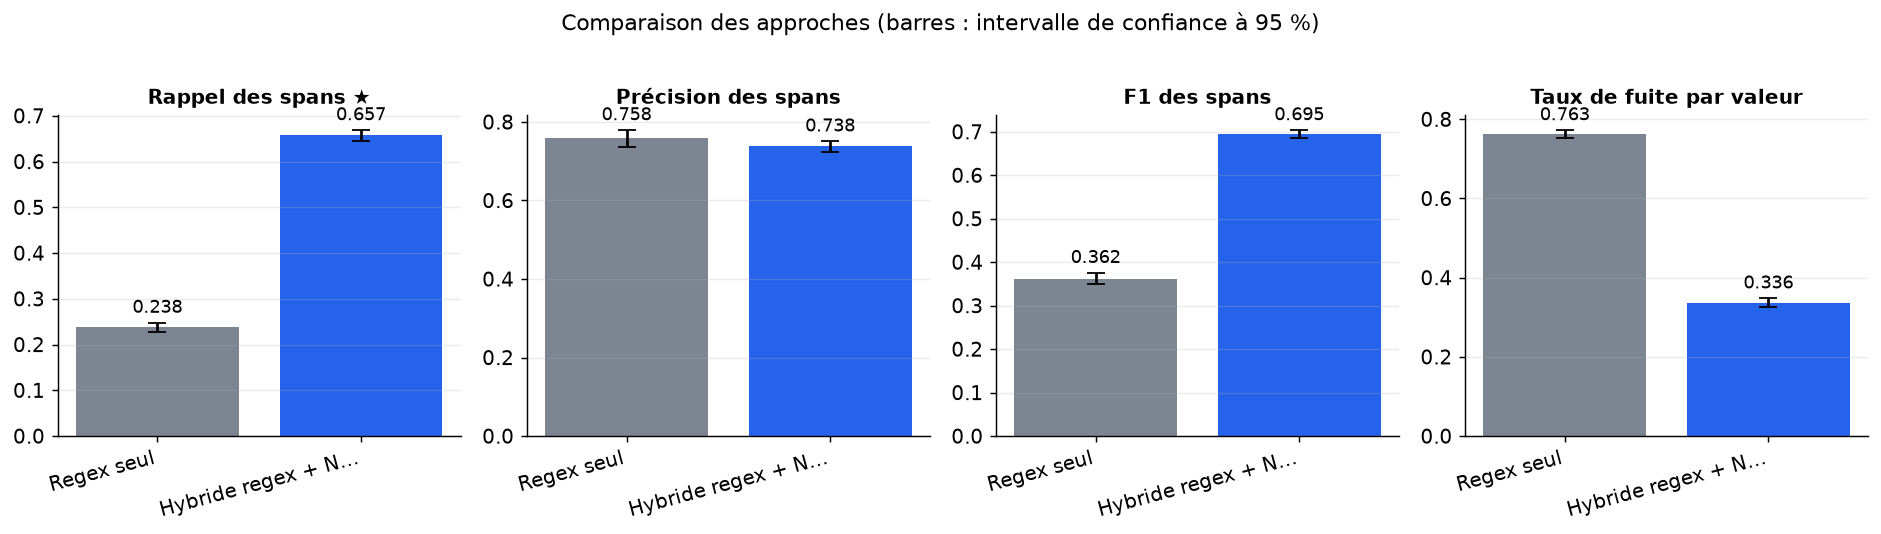

*Figure — Rappel, précision, F1 des spans et taux de fuite par valeur pour les deux approches, avec l'intervalle de confiance à 95 % (bootstrap sur les textes). Plus haut = mieux, sauf la fuite.*

In [34]:
reference_entry = approach_entry("Regex seul", "reference", reference_stats, reference_span_rows,
                                 reference_durations, f"{len(REGEX_PATTERNS)} motifs, un texte à la fois")
new_entry = approach_entry("Hybride regex + NER CamemBERT", "new", new_stats, new_span_rows, new_durations,
                           f"{NER_MODEL_ID} ({runtime_info['révision']}), {runtime_info['fils torch']} fils, "
                           f"{device()}, score minimal {NER_MIN_SCORE}")
results = save_results({
    "primary_metric": "span_recall", "direction": "max", "metric_labels": METRIC_LABELS,
    "dataset": {**dataset_info, "n_examples": int(n_evaluated)},
    "approaches": [reference_entry, new_entry],
})
display(results_table(results))
plot_comparison(results, metrics=["span_recall", "span_precision", "span_f1", "value_leak_rate"],
                caption="Rappel, précision, F1 des spans et taux de fuite par valeur pour les deux approches, "
                        "avec l'intervalle de confiance à 95 % (bootstrap sur les textes). Plus haut = mieux, sauf la fuite.")

### Prédicteurs triviaux

Un rappel élevé ne prouve rien tant qu'on ne l'a pas comparé à des stratégies naïves :
- **ne rien caviarder** : rappel nul ;
- **tout caviarder** (le texte entier devient un jeton) : rappel de 100 %, mais précision quasi nulle et texte inutilisable.

On fixe aussi les seuils de l'hypothèse, utilisés dans le verdict et dans l'analyse.

In [35]:
RECALL_REFERENCE_MAX = 0.60   # hypothèse : rappel des regex inférieur à 60 %
RECALL_NEW_MIN = 0.80         # hypothèse : rappel de l'hybride supérieur à 80 %
PRECISION_NEW_MIN = 0.70      # hypothèse : précision de l'hybride supérieure à 70 %
LATENCY_NEW_MAX_MS = 150.0    # hypothèse : latence médiane inférieure à 150 ms sur 2 cœurs

trivial_outputs = {
    "Ne rien caviarder": [([], d["text"]) for d in evaluated_docs],
    "Tout caviarder": [([{"start": 0, "end": len(d["text"]), "type": "ALL"}], "[ALL_1]") for d in evaluated_docs],
}
trivial_rows = []
for name, outputs in trivial_outputs.items():
    stats = evaluate_approach(evaluated_docs, outputs)[0]
    trivial_rows.append({"approche": name, **{k: f(stats) for k, f in METRIC_FUNCTIONS.items()}})
trivial_table = pd.DataFrame(trivial_rows).set_index("approche")
display(trivial_table.round(3))

,span_recall,span_precision,span_f1,value_leak_rate
approche,,,,
Ne rien caviarder,0.0,0.0,0.0,0.999
Tout caviarder,1.0,0.0,0.0,0.000


### Verdict

- L'hybride n'est **éligible** que si la borne basse de son F1 dépasse le meilleur F1 trivial.
- L'écart avec la référence n'est **net** que si les intervalles de confiance des rappels sont disjoints.

On confronte enfin chaque seuil de l'hypothèse au résultat, et la conclusion s'affiche d'elle-même. Si les latences ont été mesurées ailleurs que sur CPU, un avertissement le signale.

In [36]:
ref_m, new_m = reference_entry["metrics"], new_entry["metrics"]
ref_ci, new_ci = reference_entry["ci95"], new_entry["ci95"]
eligible = new_ci["span_f1"][0] > trivial_table["span_f1"].max()
clearly_better = new_ci["span_recall"][0] > ref_ci["span_recall"][1]
checks = pd.DataFrame([
    {"critère": "rappel regex < 60 %", "mesure": ref_m["span_recall"], "vérifié": ref_m["span_recall"] < RECALL_REFERENCE_MAX},
    {"critère": "rappel hybride > 80 %", "mesure": new_m["span_recall"], "vérifié": new_m["span_recall"] > RECALL_NEW_MIN},
    {"critère": "précision hybride > 70 %", "mesure": new_m["span_precision"], "vérifié": new_m["span_precision"] > PRECISION_NEW_MIN},
    {"critère": "latence médiane hybride < 150 ms", "mesure": new_m["median_latency_ms"],
     "vérifié": new_m["median_latency_ms"] < LATENCY_NEW_MAX_MS},
    {"critère": "IC des rappels disjoints (hybride > regex)", "mesure": new_ci["span_recall"][0], "vérifié": clearly_better},
])
display(checks.round(3))
if not eligible:
    verdict = "NON CONCLUANT : le F1 de l'hybride ne dépasse pas celui d'un prédicteur trivial."
elif clearly_better:
    verdict = "L'hybride détecte nettement plus de PII que les regex seules (intervalles de confiance disjoints)."
else:
    verdict = "Écart de rappel non significatif : les intervalles de confiance se recouvrent."
print("Verdict :", verdict)
if device() != "cpu":
    print("Attention : latences mesurées sur", device(), "et non sur 2 cœurs CPU ; seuil de 150 ms non comparable.")

,critère,mesure,vérifié
0,rappel regex < 60 %,0.238,True
1,rappel hybride > 80 %,0.657,False
2,précision hybride > 70 %,0.738,True
3,latence médiane hybride < 150 ms,77.930,True
4,IC des rappels disjoints (hybride > regex),0.646,True


Verdict : L'hybride détecte nettement plus de PII que les regex seules (intervalles de confiance disjoints).


## 6. Analyse des résultats

### Rappel par type de donnée personnelle

La moyenne générale masque les écarts entre types. On s'attend à ce que les deux approches soient proches sur les formats rigides (e-mail, IBAN, téléphone) et à ce que l'écart se concentre sur les **noms** et les **adresses**. La figure place les deux approches côte à côte pour chaque type ; l'effectif figure entre parenthèses.

,n_spans,recall_reference,recall_new,leak_reference,leak_new
type,,,,,
private_address,2004,0.187,0.798,0.802,0.184
private_person,1844,0.000,0.835,0.997,0.166
account_number,1157,0.340,0.344,0.660,0.651
private_date,588,0.388,0.395,0.612,0.583
secret,521,0.000,0.180,1.000,0.808
private_email,291,1.000,1.000,0.000,0.000
private_url,220,1.000,1.000,0.000,0.000
private_phone,213,0.563,0.568,0.437,0.432


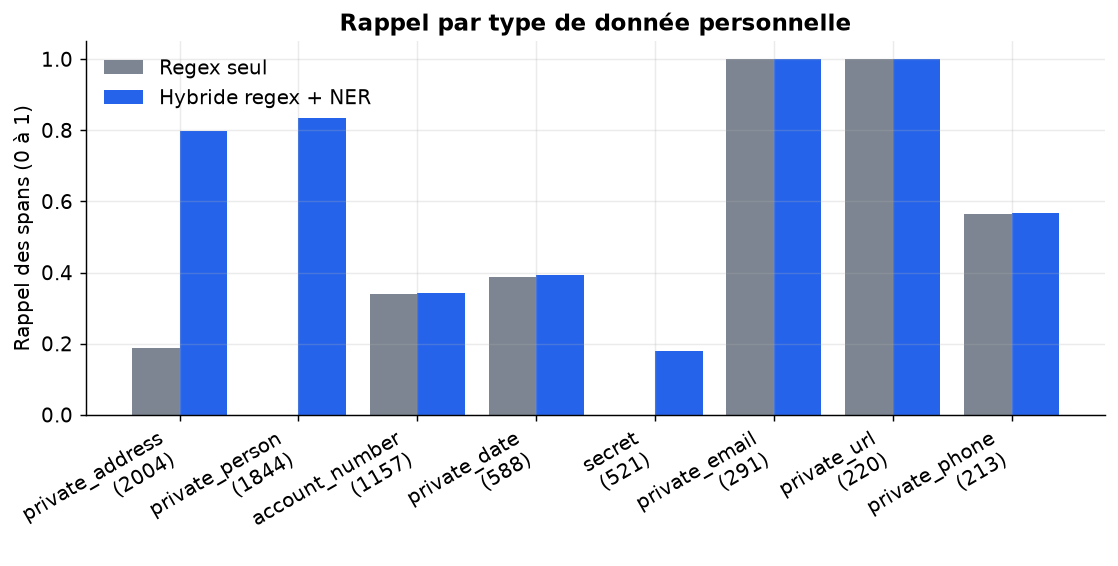

*Figure — Part des PII annotées détectées, par type (effectif entre parenthèses), pour les regex seules et l'hybride. Un écart concentré sur les noms et les lieux montre l'apport du NER.*

In [37]:
by_type = pd.DataFrame({
    "n_spans": new_span_rows.groupby("type").size(),
    "recall_reference": reference_span_rows.groupby("type")["detected"].mean(),
    "recall_new": new_span_rows.groupby("type")["detected"].mean(),
    "leak_reference": reference_span_rows.groupby("type")["leaked"].mean(),
    "leak_new": new_span_rows.groupby("type")["leaked"].mean(),
}).sort_values("n_spans", ascending=False)
display(by_type.round(3))

positions = np.arange(len(by_type))
fig, ax = plt.subplots(figsize=(max(8, 1.1 * len(by_type)), 4.5))
ax.bar(positions - 0.2, by_type["recall_reference"], width=0.4, color=COLORS["reference"], label="Regex seul")
ax.bar(positions + 0.2, by_type["recall_new"], width=0.4, color=COLORS["new"], label="Hybride regex + NER")
ax.set_xticks(positions)
ax.set_xticklabels([f"{t}\n({n})" for t, n in zip(by_type.index, by_type["n_spans"])], rotation=30, ha="right")
ax.set_ylabel("Rappel des spans (0 à 1)")
ax.set_ylim(0, 1.05)
ax.set_title("Rappel par type de donnée personnelle")
ax.legend()
fig.tight_layout()
save_figure(fig, "recall_by_type", "Part des PII annotées détectées, par type (effectif entre parenthèses), "
            "pour les regex seules et l'hybride. Un écart concentré sur les noms et les lieux montre l'apport du NER.")

### Latence selon la longueur du texte

Le coût du NER croît avec le nombre de jetons, alors que celui des regex reste négligeable. Le nuage de points montre la latence de chaque texte en fonction de sa longueur, sur une **échelle logarithmique** (chaque graduation multiplie par 10). Une droite ajustée donne le coût marginal, utile pour projeter la latence sur des textes internes plus longs.

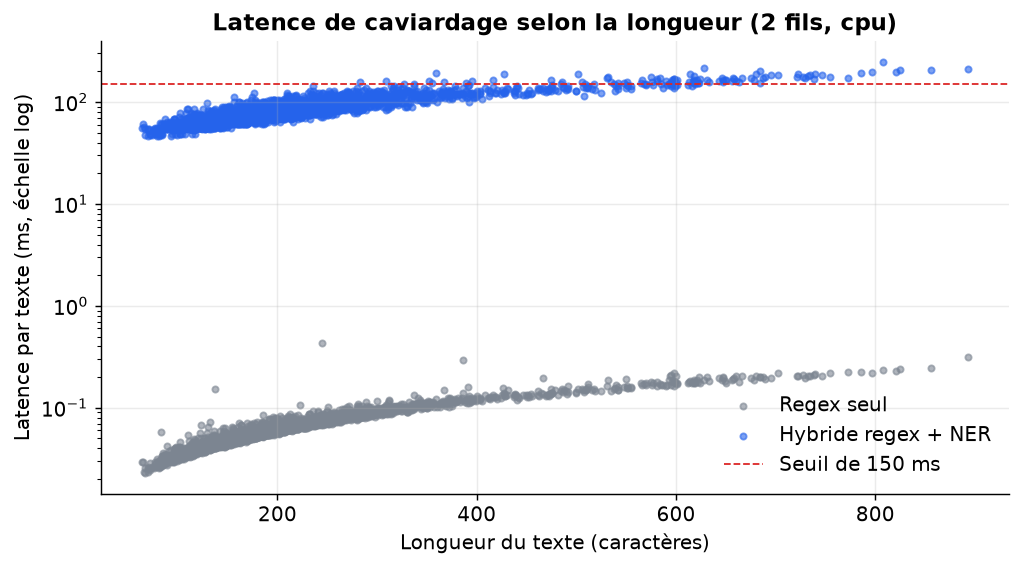

*Figure — Latence de chaque texte selon sa longueur, pour les deux approches ; la ligne pointillée marque le seuil de 150 ms de l'hypothèse.*

Coût marginal de l'hybride : environ 208.5 ms par millier de caractères


In [38]:
doc_chars = [len(d["text"]) for d in evaluated_docs]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(doc_chars, reference_durations, s=12, alpha=0.6, color=COLORS["reference"], label="Regex seul")
ax.scatter(doc_chars, new_durations, s=12, alpha=0.6, color=COLORS["new"], label="Hybride regex + NER")
ax.axhline(LATENCY_NEW_MAX_MS, color=COLORS["bad"], linestyle="--", linewidth=1, label="Seuil de 150 ms")
ax.set_yscale("log")
ax.set_xlabel("Longueur du texte (caractères)")
ax.set_ylabel("Latence par texte (ms, échelle log)")
ax.set_title(f"Latence de caviardage selon la longueur ({runtime_info['fils torch']} fils, {device()})")
ax.legend()
fig.tight_layout()
save_figure(fig, "latency_by_length", "Latence de chaque texte selon sa longueur, pour les deux approches ; "
            "la ligne pointillée marque le seuil de 150 ms de l'hypothèse.")
slope = np.polyfit(doc_chars, new_durations, 1)[0]
print(f"Coût marginal de l'hybride : environ {slope * 1000:.1f} ms par millier de caractères")

### Rappel par canal et sur-caviardage

Sur les données internes, le rappel peut varier selon le **canal**. Une transcription orale, sans majuscules ni ponctuation, gêne particulièrement le NER. On compte aussi les **zones caviardées à tort** par type de jeton : un excès de `ADDRESS` ou de `PERSON` signalerait que le NER efface des termes utiles (produits, villes citées sans lien avec la personne).

In [39]:
by_source = pd.DataFrame({
    "n_spans": new_span_rows.groupby("source").size(),
    "recall_reference": reference_span_rows.groupby("source")["detected"].mean(),
    "recall_new": new_span_rows.groupby("source")["detected"].mean(),
})
display(by_source.round(3))
over_redaction = pd.DataFrame({
    "faux_positifs_regex": reference_false.groupby("type").size(),
    "faux_positifs_hybride": new_false.groupby("type").size(),
}).fillna(0).astype(int)
display(over_redaction)

,n_spans,recall_reference,recall_new
source,,,
public,6838,0.238,0.657


,faux_positifs_regex,faux_positifs_hybride
type,,
ADDRESS,13,376
CARD,106,106
DATE,12,12
IBAN,3,3
IP,327,327
PERSON,0,573


### Exemples d'erreurs (phase publique seulement)

Pour comprendre ce qui échappe encore à l'hybride, on affiche quelques PII **manquées** et quelques zones **caviardées à tort**, avec 40 caractères de contexte et la valeur entre « ». Pour ne rien exposer, ces exemples ne s'affichent qu'en phase publique ; en phase interne, seuls les effectifs sont donnés.

In [40]:
N_ERROR_EXAMPLES = 8  # nombre d'exemples affichés par catégorie d'erreur


def with_context(row: pd.Series) -> str:
    """Extrait du texte autour de la zone, la zone marquée par des guillemets."""
    text = evaluated_docs[int(row["doc"])]["text"]
    start, end = int(row["start"]), int(row["end"])
    return f"…{text[max(0, start - 40):start]}«{text[start:end]}»{text[end:end + 40]}…"


missed = new_span_rows[~new_span_rows["detected"]] if len(new_span_rows) else new_span_rows
print(f"PII manquées par l'hybride : {len(missed)} ; zones caviardées à tort : {len(new_false)}")
if PHASE == "public":
    for title, frame in [("PII manquées", missed), ("Caviardées à tort", new_false)]:
        if len(frame):
            shown = frame.sample(min(N_ERROR_EXAMPLES, len(frame)), random_state=SEED)
            print(f"\n{title} :")
            display(pd.DataFrame({"type": shown["type"].values,
                                  "contexte": [with_context(row) for _, row in shown.iterrows()]}))

PII manquées par l'hybride : 2344 ; zones caviardées à tort : 1397

PII manquées :


,type,contexte
0,private_address,… nouvelle résidence. Le bâtiment numéro «12» ...
1,secret,"…aisons de sécurité, veuillez fournir le «5597..."
2,account_number,…Avez-vous utilisé le «330» pour la vérificati...
3,private_address,… service d'urologie de notre clinique à «7999...
4,private_address,…J'habite à Idaho avec le code postal «74596-1...
5,account_number,"…alculating-landscape.net/, please input «5999..."
6,private_person,…es mises à jour des soins palliatifs de «Anas...
7,private_address,"… Madame Fatima Al-Hassan, qui habite au «19B»..."



Caviardées à tort :


,type,contexte
0,PERSON,"…Je m'appelle «Lucie», et je r side actuelleme..."
1,PERSON,"…Dans son étude récente, «Dupont» analyse les ..."
2,PERSON,…sse robuste tel que 'L3Forteress@2024'. «Jean...
3,ADDRESS,"… Genève, attire des talents de toute la «Suis..."
4,ADDRESS,"…eg, dans la ville de Winterthour, 8400, «cant..."
5,CARD,…aiement avec un numéro masqué contenant «4419...
6,IP,…rer d'utiliser une connexion sécurisée («addb...
7,IP,…aven. Veuillez accéder aux fichiers sur «3.24...


### À retenir

- **Si** l'intervalle de confiance du rappel de l'hybride est au-dessus de celui des regex, l'ajout du NER français se justifie. La figure par type indique alors d'où vient le gain (en principe noms et lieux). Si les intervalles se recouvrent, le verdict affiché est « non significatif ».
- **Si** le pire rappel par type reste bas, même avec un rappel global élevé, un type de donnée continue de fuir et le caviardeur ne peut pas servir tel quel pour ce type.
- **Si** la précision de l'hybride passe sous 70 %, le NER efface trop de termes utiles. Il faut alors une liste d'exclusion ou un score minimal plus haut, réglés sur les données de l'environnement cible.
- **Si** la latence médiane reste sous 150 ms sur 2 cœurs, le surcoût est faible devant un appel LLM de plusieurs secondes. Le nuage par longueur aide à le projeter sur des textes internes plus longs.
- Ces chiffres viennent de textes synthétiques ou factices. Ils ne valent **pas** preuve de conformité : seule une annotation des données internes, par type et par canal, permet de valider un usage.

## 7. Bilan

> **Verdict** (confiance elevee). À l'échelle complète (2 926 textes français annotés, CPU), l'hybride regex + NER CamemBERT atteint un rappel de 0,657 (IC 95 % 0,646–0,669) contre 0,238 (0,228–0,248) pour les regex seules : l'écart est net, les intervalles sont disjoints, et les deux approches sont évaluées sur les mêmes textes. La précision est comparable (0,738 contre 0,758), la latence médiane de 78 ms (p95 137 ms) reste sous 150 ms pour des textes courts. L'hypothèse n'est toutefois qu'en partie confirmée : le rappel de 80 % n'est pas atteint, 34 % des valeurs fuitent encore, et le pire rappel par type est de 0,18 (secrets). Le gain vient presque entièrement des noms et adresses ; comptes, dates et téléphones ne progressent pas. Les chiffres absolus sont à lire avec prudence, car les annotations du jeu synthétique sont bruitées. Ils ne sont pas comparables à ceux de la source (100 % contre 88,9 % sur des CV anglais), seule la direction de l'effet est la même.

*Échelle complète : 2926 exemples de test de `TheoDB/french-pii-eval` (CPU, 4 cœurs, 4 min). La mécanique avait d'abord été validée à l'échelle réduite (150 exemples, CPU).*

| Approche | Rappel des spans ★ ↑ | Précision des spans ↑ | F1 des spans ↑ | Taux de fuite par valeur ↓ | Pire rappel par type ↑ | Latence médiane (ms) ↓ | Latence p95 (ms) ↓ | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|---|---|
| Regex seul (référence) | 0,238 [0,228 ; 0,248] | **0,758 [0,737 ; 0,78]** | 0,362 [0,349 ; 0,376] | 0,763 [0,752 ; 0,773] | 0 | **0,06** | **0,14** | 0,06 |
| Hybride regex + NER CamemBERT (nouvelle approche) | **0,657 [0,646 ; 0,669]** | 0,738 [0,724 ; 0,751] | **0,695 [0,685 ; 0,704]** | **0,336 [0,325 ; 0,348]** | **0,18** | 77,9 | 137 | 77,9 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- L'hybride fait bien mieux que les regex seules, mais il n'atteint pas 80 % de rappel : environ un tiers des valeurs personnelles restent lisibles après caviardage. Il ne suffit pas tel quel pour protéger des données.
- Le rappel global dépend de la proportion de noms et d'adresses dans le jeu. Avec peu de noms, l'avantage du NER serait bien plus faible. Les mots de passe, numéros de compte et dates restent largement non caviardés par les deux approches.
- La précision de 0,74 est probablement sous-estimée, car des noms réels non annotés sont comptés comme erreurs. Le rappel absolu l'est aussi pour les types dont l'annotation est douteuse. Seul l'écart entre approches est fiable.

**Limites**

- Les textes du jeu public sont synthétiques, dérivés d'ai4privacy, avec des noms et des IBAN souvent étrangers : les résultats ne se transposent pas directement aux données internes.
- Le jeu public n'a pas de licence déclarée : il faut la valider avant tout usage hors expérience.
- Les entités LOC du NER sont assimilées à des adresses. Une ville citée sans lien avec la personne est alors comptée comme sur-caviardage, ce qui pèse sur la précision.
- Les latences sont mesurées sur 2 fils CPU de la machine d'exécution. Sur un autre processeur, ou avec des textes plus longs, elles peuvent être sensiblement différentes.
- Un bon rappel ne vaut pas preuve de conformité : il faut le valider par type et par canal sur des données internes annotées.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite, l'évaluation porte sur 150 textes tirés au hasard au lieu des 2 926 du split test. Le budget de temps de la boucle hybride passe de 900 s à 300 s. Le modèle et les motifs sont identiques aux deux échelles.

**Améliorations possibles**

- La latence médiane d'environ 78 ms vaut pour des textes courts. Elle croît vite avec la longueur : des e-mails ou transcriptions de plus de quelques centaines de caractères dépasseront probablement 150 ms.
- Le rappel faible des regex sur téléphones et dates peut venir de formats étrangers présents dans le jeu. Il ne reflète pas forcément ce que donneraient des textes strictement français.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).